In [ ]:
# ---- 1a. Install & imports ----
!pip install kaggle -q

import os
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.mixed_precision import set_global_policy

In [ ]:
# ---- 1b. Mixed precision — set ONCE, globally, so both the baseline CNN
# and MobileNetV2 (trained later) benefit from faster GPU training ----
set_global_policy('mixed_float16')
print("Mixed precision policy:", tf.keras.mixed_precision.global_policy())

# ---- 1c. Mount Google Drive (for saving models/results throughout) ----
from google.colab import drive
drive.mount('/content/drive')

Mixed precision policy: <DTypePolicy "mixed_float16">
Mounted at /content/drive


In [ ]:
# ---- 1d. Download dataset from Kaggle ----
# If you already have kaggle.json set up from before, this step is skipped automatically.
# >>> ADJUST the dataset slug below if yours is different <<<
from google.colab import files
if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Upload your kaggle.json file:")
    uploaded = files.upload()
    os.makedirs('/root/.kaggle', exist_ok=True)
    for fn in uploaded.keys():
        os.rename(fn, '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)

!kaggle datasets download -d xhlulu/140k-real-and-fake-faces -p dataset --unzip

# ---- 1e. Config — used throughout the rest of the notebook ----
BASE_DIR = "dataset/real_vs_fake/real-vs-fake"
IMG_SIZE = (224, 224)
BATCH_SIZE = 128
EPOCHS = 15

Upload your kaggle.json file:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces
License(s): other
100% 3.75G/3.75G [03:45<00:00, 17.8MB/s]



In [ ]:
# ============================================================
# FIX: Rebuild datasets WITHOUT augmentation in the tf.data pipeline.
# Augmentation moves into the model instead (GPU-side, much faster).
# No re-download needed — the files are already on local disk.
# ============================================================

import os
import tensorflow as tf
from tensorflow.keras import layers

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "train"),
    labels="inferred", label_mode="binary", class_names=["real", "fake"],
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True, seed=42
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "valid"),
    labels="inferred", label_mode="binary", class_names=["real", "fake"],
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "test"),
    labels="inferred", label_mode="binary", class_names=["real", "fake"],
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
)

normalization_layer = layers.Rescaling(1./255)

def prepare(ds):
    ds = ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = prepare(train_ds)
val_ds = prepare(val_ds)
test_ds = prepare(test_ds)

print("Rebuilt train_ds/val_ds/test_ds — augmentation removed from the pipeline.")
print("(It now lives inside the model instead — see the updated Section 3.)")


Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Rebuilt train_ds/val_ds/test_ds — augmentation removed from the pipeline.
(It now lives inside the model instead — see the updated Section 3.)


In [ ]:
# EDA — Deepfake / AI-Generated Image Detector
# 7 sections. Paste EACH section as its own cell (add a Markdown
# heading above each, e.g. "## 1. Class Balance", for a clean report).
# Assumes BASE_DIR is already defined from your training notebook.
# ============================================================

import os
import random
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2

random.seed(42)

Split     Real      Fake      Total     
train     50000     50000     100000    
valid     10000     10000     20000     
test      10000     10000     20000     


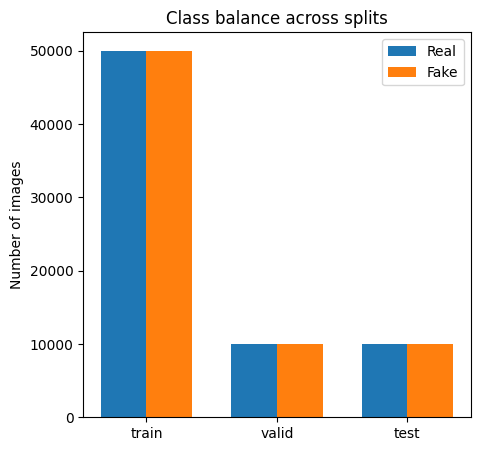

In [ ]:
# ============================================================
# SECTION 1: Class balance
# ============================================================
splits = ["train", "valid", "test"]
classes = ["real", "fake"]

print(f"{'Split':<10}{'Real':<10}{'Fake':<10}{'Total':<10}")
counts = {}
for split in splits:
    counts[split] = {}
    for cls in classes:
        path = os.path.join(BASE_DIR, split, cls)
        counts[split][cls] = len(os.listdir(path))
    total = sum(counts[split].values())
    print(f"{split:<10}{counts[split]['real']:<10}{counts[split]['fake']:<10}{total:<10}")

x = np.arange(len(splits))
width = 0.35
real_counts = [counts[s]['real'] for s in splits]
fake_counts = [counts[s]['fake'] for s in splits]

plt.figure(figsize=(5, 5))
plt.bar(x - width/2, real_counts, width, label='Real')
plt.bar(x + width/2, fake_counts, width, label='Fake')
plt.xticks(x, splits)
plt.ylabel('Number of images')
plt.title('Class balance across splits')
plt.legend()
plt.savefig('/content/drive/MyDrive/eda_class_balance.png', dpi=150, bbox_inches='tight')
plt.show()

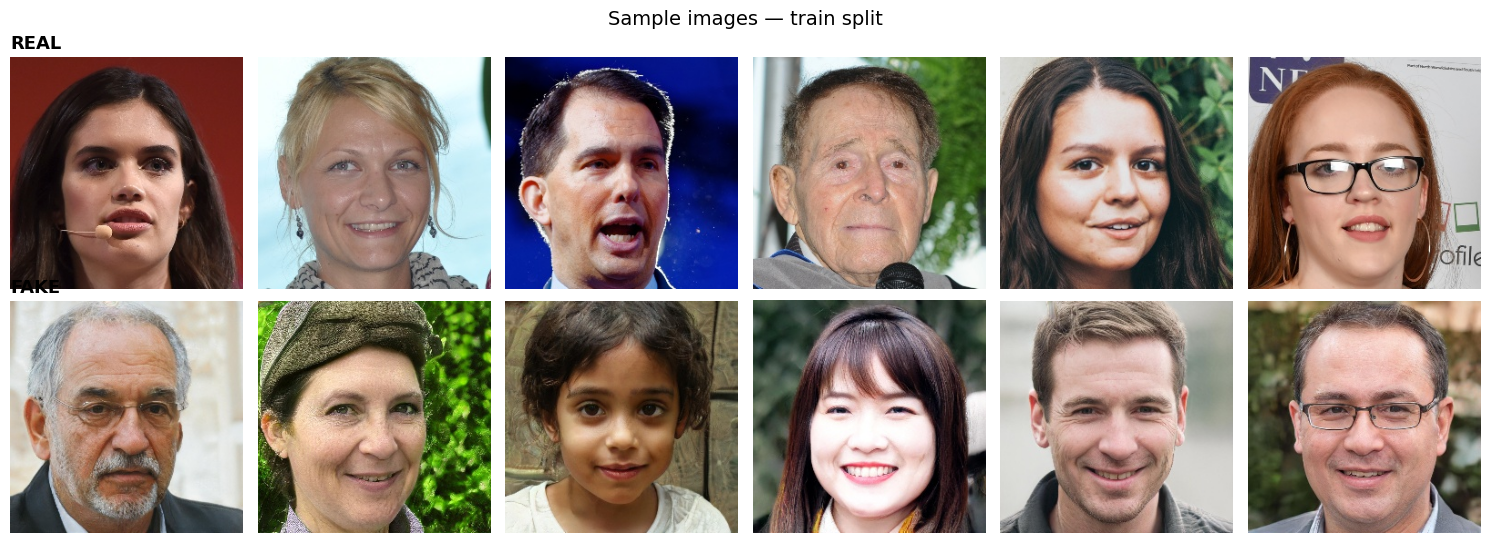

In [ ]:
# ============================================================
# SECTION 2: Sample visualization
# ============================================================
def show_samples(split, n=6):
    fig, axes = plt.subplots(2, n, figsize=(2.5 * n, 5.5))
    for row, cls in enumerate(["real", "fake"]):
        path = os.path.join(BASE_DIR, split, cls)
        files = random.sample(os.listdir(path), n)
        for col, f in enumerate(files):
            img = Image.open(os.path.join(path, f))
            axes[row, col].imshow(img)
            axes[row, col].axis('off')
        axes[row, 0].set_title(f"{cls.upper()}", loc='left', fontsize=13, fontweight='bold')
    plt.suptitle(f"Sample images — {split} split", fontsize=14)
    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/eda_sample_images.png', dpi=150, bbox_inches='tight')
    plt.show()

show_samples("train", n=6)


In [ ]:
# ============================================================
# SECTION 3: Resolution / dimension check
# ============================================================
def check_resolutions(split, cls, n=200):
    path = os.path.join(BASE_DIR, split, cls)
    files = os.listdir(path)
    sample_files = random.sample(files, min(n, len(files)))
    sizes = []
    for f in sample_files:
        with Image.open(os.path.join(path, f)) as img:
            sizes.append(img.size)  # (width, height)
    return sizes

real_sizes = check_resolutions("train", "real")
fake_sizes = check_resolutions("train", "fake")

unique_real = set(real_sizes)
unique_fake = set(fake_sizes)
print(f"Unique resolutions in real sample: {unique_real}")
print(f"Unique resolutions in fake sample: {unique_fake}")

if len(unique_real) == 1 and len(unique_fake) == 1:
    print("All sampled images share the same resolution — no resizing inconsistency.")
else:
    widths = [s[0] for s in real_sizes + fake_sizes]
    heights = [s[1] for s in real_sizes + fake_sizes]
    plt.figure(figsize=(6, 4))
    plt.hist(widths, bins=20, alpha=0.6, label='Width')
    plt.hist(heights, bins=20, alpha=0.6, label='Height')
    plt.legend()
    plt.title('Image dimension distribution')
    plt.savefig('/content/drive/MyDrive/eda_resolution.png', dpi=150, bbox_inches='tight')
    plt.show()

Unique resolutions in real sample: {(256, 256)}
Unique resolutions in fake sample: {(256, 256)}
All sampled images share the same resolution — no resizing inconsistency.


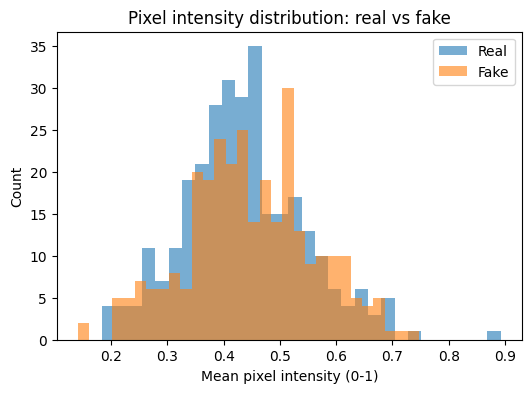

Real mean intensity: 0.435 | Fake mean intensity: 0.447


In [ ]:
# ============================================================
# SECTION 4: Pixel intensity distribution
# ============================================================
def get_mean_intensities(split, cls, n=300):
    path = os.path.join(BASE_DIR, split, cls)
    files = random.sample(os.listdir(path), min(n, len(os.listdir(path))))
    means = []
    for f in files:
        img = Image.open(os.path.join(path, f)).convert('RGB').resize((224, 224))
        arr = np.array(img) / 255.0
        means.append(arr.mean())
    return means

real_means = get_mean_intensities("train", "real")
fake_means = get_mean_intensities("train", "fake")

plt.figure(figsize=(6, 4))
plt.hist(real_means, bins=30, alpha=0.6, label='Real')
plt.hist(fake_means, bins=30, alpha=0.6, label='Fake')
plt.xlabel('Mean pixel intensity (0-1)')
plt.ylabel('Count')
plt.title('Pixel intensity distribution: real vs fake')
plt.legend()
plt.savefig('/content/drive/MyDrive/eda_pixel_intensity.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Real mean intensity: {np.mean(real_means):.3f} | Fake mean intensity: {np.mean(fake_means):.3f}")

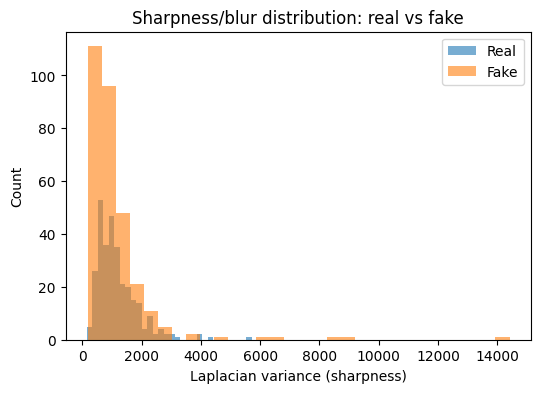

Real mean sharpness: 1167.7 | Fake mean sharpness: 1119.6


In [ ]:
# ============================================================
# SECTION 5: Sharpness / blur check (Laplacian variance)
# ============================================================
def get_sharpness_scores(split, cls, n=300):
    path = os.path.join(BASE_DIR, split, cls)
    files = random.sample(os.listdir(path), min(n, len(os.listdir(path))))
    scores = []
    for f in files:
        img = cv2.imread(os.path.join(path, f), cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        scores.append(cv2.Laplacian(img, cv2.CV_64F).var())
    return scores

real_sharpness = get_sharpness_scores("train", "real")
fake_sharpness = get_sharpness_scores("train", "fake")

plt.figure(figsize=(6, 4))
plt.hist(real_sharpness, bins=30, alpha=0.6, label='Real')
plt.hist(fake_sharpness, bins=30, alpha=0.6, label='Fake')
plt.xlabel('Laplacian variance (sharpness)')  ###### Uses Laplacian to calculate sharpness    Higher-Sharp
plt.ylabel('Count')
plt.title('Sharpness/blur distribution: real vs fake')
plt.legend()
plt.savefig('/content/drive/MyDrive/eda_sharpness.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Real mean sharpness: {np.mean(real_sharpness):.1f} | Fake mean sharpness: {np.mean(fake_sharpness):.1f}")

In [ ]:
# ============================================================
# SECTION 6: Duplicate / near-duplicate check (train vs test)
# NOTE: hashes the full folders — can take a couple of minutes.
# Pass a `limit` to get_file_hashes(...) for a faster partial check.
# ============================================================
def get_file_hashes(split, cls, limit=None):
    path = os.path.join(BASE_DIR, split, cls)
    files = os.listdir(path)
    if limit:
        files = files[:limit]
    hashes = {}
    for f in files:
        fpath = os.path.join(path, f)
        with open(fpath, 'rb') as file:
            h = hashlib.md5(file.read()).hexdigest()
        hashes[h] = fpath
    return hashes

print("Hashing training images (this may take a couple of minutes)...")
train_hashes = {}
train_hashes.update(get_file_hashes("train", "real"))
train_hashes.update(get_file_hashes("train", "fake"))

print("Hashing test images...")
test_hashes = {}
test_hashes.update(get_file_hashes("test", "real"))
test_hashes.update(get_file_hashes("test", "fake"))

overlap = set(train_hashes.keys()) & set(test_hashes.keys())
print(f"\nExact duplicate images between train and test: {len(overlap)}")
if overlap:
    print("Example duplicate pairs:")
    for h in list(overlap)[:5]:
        print(f"  Train: {train_hashes[h]}  <->  Test: {test_hashes[h]}")
else:
    print("No exact duplicates found between train and test splits — good, your test accuracy isn't inflated by leakage.")


Hashing training images (this may take a couple of minutes)...
Hashing test images...

Exact duplicate images between train and test: 0
No exact duplicates found between train and test splits — good, your test accuracy isn't inflated by leakage.


In [ ]:
# ============================================================
# SECTION 7: Corrupted / unreadable file check
# NOTE: scans the full dataset — can take a couple of minutes.
# ============================================================
def check_corrupted(split, cls):
    path = os.path.join(BASE_DIR, split, cls)
    corrupted = []
    for f in os.listdir(path):
        fpath = os.path.join(path, f)
        try:
            img = Image.open(fpath)
            img.verify()
        except Exception as e:
            corrupted.append((fpath, str(e)))
    return corrupted

all_corrupted = []
for split in splits:
    for cls in classes:
        corrupted = check_corrupted(split, cls)
        all_corrupted.extend(corrupted)
        print(f"{split}/{cls}: {len(corrupted)} corrupted files found")

print(f"\nTotal corrupted/unreadable images: {len(all_corrupted)}")
if all_corrupted:
    for fpath, err in all_corrupted[:10]:
        print(f"  {fpath}: {err}")
else:
    print("No corrupted files found.")


train/real: 0 corrupted files found
train/fake: 0 corrupted files found
valid/real: 0 corrupted files found
valid/fake: 0 corrupted files found
test/real: 0 corrupted files found
test/fake: 0 corrupted files found

Total corrupted/unreadable images: 0
No corrupted files found.


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 267s 162ms/step - accuracy: 0.5573 - loss: 0.6831 - val_accuracy: 0.5920 - val_loss: 0.6693
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 237s 152ms/step - accuracy: 0.6181 - loss: 0.6549 - val_accuracy: 0.6372 - val_loss: 0.6398
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 263s 152ms/step - accuracy: 0.6670 - loss: 0.6134 - val_accuracy: 0.6806 - val_loss: 0.6027
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 239s 153ms/step - accuracy: 0.7071 - loss: 0.5706 - val_accuracy: 0.6788 - val_loss: 0.6070
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 243s 155ms/step - accuracy: 0.7326 - loss: 0.5369 - val_accuracy: 0.7137 - val_loss: 0.5654
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 232s 148ms/step - accuracy: 0.7533 - loss: 0.5087 - val_accuracy: 0.7396 - val_loss: 0.5401
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 237s 152ms/step - accuracy: 0.7709 - loss: 0.4833 - val_accuracy: 0.7819 - val_loss: 0.4574
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 234s 150ms/step - ac


Baseline CNN test accuracy: 81.72%
Saved baseline model to Drive as baseline_cnn.h5


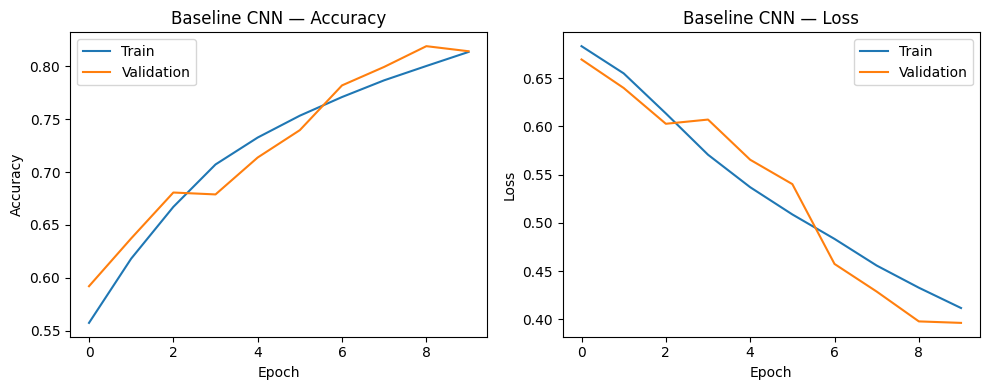

In [ ]:
# ============================================================
# SECTION 3: BASELINE MODEL (CNN from scratch)
# Deepfake / AI-Generated Face Detector
#
# A simple, randomly-initialized CNN — no pretrained weights.
# Its accuracy becomes the reference point for Section 5, where
# we'll compare it against MobileNetV2 transfer learning.
#
# Augmentation now lives INSIDE the model (first layer) instead of
# in the tf.data pipeline — runs on GPU, much faster.
# ============================================================

from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# ---- 3a. Augmentation block — GPU-side, training-time only ----
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="augmentation")

# ---- 3b. Simple CNN architecture ----
baseline_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid', dtype='float32')  # float32 output — safe under the mixed_precision policy from Section 1
])

baseline_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
baseline_model.summary()

# ---- 3c. Train ----
baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

# ---- 3d. Evaluate on the test set ----
baseline_test_loss, baseline_test_acc = baseline_model.evaluate(test_ds)
print(f"\nBaseline CNN test accuracy: {baseline_test_acc * 100:.2f}%")

# ---- 3e. Save for later (Section 5 comparison, and as a backup) ----
baseline_model.save('/content/drive/MyDrive/baseline_cnn.h5')
print("Saved baseline model to Drive as baseline_cnn.h5")

# ---- 3f. Training curves ----
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(baseline_history.history['accuracy'], label='Train')
plt.plot(baseline_history.history['val_accuracy'], label='Validation')
plt.title('Baseline CNN — Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(baseline_history.history['loss'], label='Train')
plt.plot(baseline_history.history['val_loss'], label='Validation')
plt.title('Baseline CNN — Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/baseline_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
baseline_model.save('/content/drive/MyDrive/baseline_cnn.h5')
print("Model saved successfully!")

Model saved successfully!


In [ ]:
# CELL 1: download extra face dataset
import os
from google.colab import files

if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Upload your kaggle.json")
    uploaded = files.upload()
    os.makedirs('/root/.kaggle', exist_ok=True)
    for fn in uploaded:
        os.rename(fn, '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)

!kaggle datasets download -d ciplab/real-and-fake-face-detection -p extra_faces --unzip

print("Done. Folders:", os.listdir("extra_faces") if os.path.exists("extra_faces") else "NOT FOUND")

Upload your kaggle.json


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/ciplab/real-and-fake-face-detection
License(s): CC-BY-NC-SA-4.0
100% 431M/431M [00:25<00:00, 17.5MB/s]

Done. Folders: ['real_and_fake_face_detection', 'real_and_fake_face']


In [ ]:
# CELL 2: make mixed face training folder
import os, shutil, random
random.seed(42)

FACE_TRAIN = "dataset/real_vs_fake/real-vs-fake/train"
MIXED_DIR = "mixed_faces_train"

def find_dir(root, keys):
    if not os.path.exists(root):
        return None
    for r, ds, fs in os.walk(root):
        name = os.path.basename(r).lower()
        if any(k in name for k in keys):
            imgs = [f for f in fs if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
            if len(imgs) > 50:
                return r
    return None

EXTRA_REAL = find_dir("extra_faces", ["real"])
EXTRA_FAKE = find_dir("extra_faces", ["fake"])
print("EXTRA_REAL:", EXTRA_REAL)
print("EXTRA_FAKE:", EXTRA_FAKE)

if os.path.exists(MIXED_DIR):
    shutil.rmtree(MIXED_DIR)
os.makedirs(MIXED_DIR + "/real", exist_ok=True)
os.makedirs(MIXED_DIR + "/fake", exist_ok=True)

def copy_random(src, dst, n, prefix):
    if src is None or not os.path.exists(src):
        return 0
    files = [f for f in os.listdir(src) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    n = min(n, len(files))
    for f in random.sample(files, n):
        shutil.copy(os.path.join(src, f), os.path.join(dst, prefix + "_" + f))
    return n

n1 = copy_random(FACE_TRAIN + "/real", MIXED_DIR + "/real", 25000, "f140")
n2 = copy_random(FACE_TRAIN + "/fake", MIXED_DIR + "/fake", 20000, "f140")
n3 = copy_random(EXTRA_REAL, MIXED_DIR + "/real", 10000, "extra")
n4 = copy_random(EXTRA_FAKE, MIXED_DIR + "/fake", 15000, "extra")

print("real images:", len(os.listdir(MIXED_DIR + "/real")))
print("fake images:", len(os.listdir(MIXED_DIR + "/fake")))
print("total:", n1 + n2 + n3 + n4)

EXTRA_REAL: extra_faces/real_and_fake_face_detection/real_and_fake_face/training_real
EXTRA_FAKE: extra_faces/real_and_fake_face_detection/real_and_fake_face/training_fake
real images: 26081
fake images: 20960
total: 47041


In [ ]:
# ============================================================
# CELL 3 FIXED: MobileNet training (augment THEN preprocess)
# ============================================================
import os
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

IMG_SIZE = (224, 224)
BATCH_SIZE = 128
BASE_DIR = "dataset/real_vs_fake/real-vs-fake"
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

# 1) Load RAW images (0-255), no preprocess yet
def make_raw_ds(path, names, shuffle=True, seed=None):
    return tf.keras.utils.image_dataset_from_directory(
        path,
        labels="inferred",
        label_mode="binary",
        class_names=names,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=seed
    )

train_raw = make_raw_ds("mixed_faces_train", ["real", "fake"], True, 42)
val_raw   = make_raw_ds(BASE_DIR + "/valid", ["real", "fake"], False)
test_raw  = make_raw_ds(BASE_DIR + "/test",  ["real", "fake"], False)

# 2) Light augmentation on RAW images only
aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.06),
], name="aug")

# 3) Augment first, THEN preprocess
def prep_train(x, y):
    x = aug(x, training=True)
    x = preprocess_input(x)
    return x, y

def prep_eval(x, y):
    x = preprocess_input(x)
    return x, y

train_ds = train_raw.map(prep_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds   = val_raw.map(prep_eval, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
test_ds  = test_raw.map(prep_eval, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

# 4) Model
base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base.trainable = False

wd = 1e-4
x = base.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
x = layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(wd))(x)
x = layers.Dropout(0.40)(x)
x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(wd))(x)
x = layers.Dropout(0.25)(x)
out = layers.Dense(1, activation="sigmoid", dtype="float32")(x)

model = models.Model(base.input, out)
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cbs = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7)
]

print("Stage 1: frozen")
h1 = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=cbs)

# Stage 2
base.trainable = True
for layer in base.layers[:100]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Stage 2: fine-tune")
h2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=16,
    initial_epoch=len(h1.history["loss"]),
    callbacks=cbs
)

print("Testing...")
loss, acc = model.evaluate(test_ds)
print("Face test accuracy:", round(acc * 100, 2), "%")

model.save("/content/drive/MyDrive/mobilenetv2_internet_faces.h5")
print("Saved to Drive")

Found 47041 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Stage 1: frozen
Epoch 1/8
368/368 ━━━━━━━━━━━━━━━━━━━━ 493s 1s/step - accuracy: 0.6896 - loss: 0.6423 - val_accuracy: 0.7463 - val_loss: 0.5774 - learning_rate: 0.0010
Epoch 2/8
368/368 ━━━━━━━━━━━━━━━━━━━━ 453s 1s/step - accuracy: 0.7290 - loss: 0.5841 - val_accuracy: 0.7657 - val_loss: 0.5437 - learning_rate: 0.0010
Epoch 3/8
368/368 ━━━━━━━━━━━━━━━━━━━━ 450s 1s/step - accuracy: 0.7373 - loss: 0.5663 - val_accuracy: 0.7854 - val_loss: 0.5196 - learning_rate: 0.0010
Epoch 4/8
368/368 ━━━━━━━━━━━━━━━━━━━━ 457s 1s/step - accuracy: 0.7463 - loss: 0.5524 - val_accuracy: 0.7670 - val_loss: 0.5400 - learning_rate: 0.0010
Epoch 5/8
368/368 ━━━━━━━━━━━━━━━━━━━━ 456s 1s/step - accuracy: 0.7525 - loss: 0.5403 - val_accuracy: 0.7840 - val_loss: 0.5157 - learning_rate: 0.0010
Epoch 6/8
368/368 ━━━━━━━━━━━━━━━━━━━━ 458s 1s/step - accuracy: 0.7565 - loss: 0.5328 - val_accura

Face test accuracy: 90.89 %
Saved to Drive


In [ ]:
# CELL 4: test your own internet images
import numpy as np
from PIL import Image
from google.colab import files
from tensorflow.keras.models import load_model
import tensorflow as tf

model = load_model("/content/drive/MyDrive/mobilenetv2_internet_faces.h5")
preprocess = tf.keras.applications.mobilenet_v2.preprocess_input

print("Upload image(s)")
uploaded = files.upload()

for name in uploaded:
    img = Image.open(name).convert("RGB").resize((224, 224))
    arr = np.array(img).astype("float32")
    x = preprocess(arr)   # important: do not divide by 255
    p = float(model.predict(np.expand_dims(x, 0), verbose=0).flatten()[0])
    label = "FAKE" if p > 0.5 else "REAL"
    print(name, "-> P(fake) =", round(p, 4), "=>", label)

In [ ]:
model.save('/content/drive/MyDrive/mobilenetv2_finetuned.h5')
print("Model saved successfully!")

Model saved successfully!


In [ ]:
# ============================================================
# RECOVERY: Reload saved models (NO retraining)
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
from tensorflow.keras.models import load_model

# 1) Baseline CNN
try:
    baseline_model
    print("baseline_model already in memory")
except NameError:
    print("Loading baseline CNN from Drive...")
    baseline_model = load_model('/content/drive/MyDrive/baseline_cnn.h5')
    print("Baseline CNN loaded")

# 2) NEW MobileNet (internet faces model)
try:
    model
    print("model already in memory")
except NameError:
    print("Loading internet-faces MobileNet from Drive...")
    model = load_model('/content/drive/MyDrive/mobilenetv2_internet_faces.h5')
    print("Internet-faces MobileNet loaded")

preprocess_mobilenet = tf.keras.applications.mobilenet_v2.preprocess_input
IMG_SIZE = (224, 224)

print("\nAll set.")
print("- baseline_model : ready (uses /255)")
print("- model          : internet faces MobileNet (uses preprocess_mobilenet)")
print("IMPORTANT: DO NOT divide by 255 for MobileNet. Use preprocess_mobilenet().")

Mounted at /content/drive
Loading baseline CNN from Drive...


Baseline CNN loaded
Loading internet-faces MobileNet from Drive...


Internet-faces MobileNet loaded

All set.
- baseline_model : ready (uses /255)
- model          : internet faces MobileNet (uses preprocess_mobilenet)
IMPORTANT: DO NOT divide by 255 for MobileNet. Use preprocess_mobilenet().


In [ ]:
# ============================================================
# Re-download 140K faces dataset (needed after runtime reset)
# ============================================================
import os
from google.colab import files

if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Upload kaggle.json")
    uploaded = files.upload()
    os.makedirs('/root/.kaggle', exist_ok=True)
    for fn in uploaded:
        os.rename(fn, '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)

!kaggle datasets download -d xhlulu/140k-real-and-fake-faces -p dataset --unzip

BASE_DIR = "dataset/real_vs_fake/real-vs-fake"
print("test exists:", os.path.exists(os.path.join(BASE_DIR, "test")))
print("folders:", os.listdir(BASE_DIR) if os.path.exists(BASE_DIR) else "MISSING")

Dataset URL: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces
License(s): other
100% 3.75G/3.75G [04:13<00:00, 15.8MB/s]

test exists: True
folders: ['test', 'valid', 'train']


Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Evaluating Baseline CNN...
Evaluating Internet-Faces MobileNetV2...


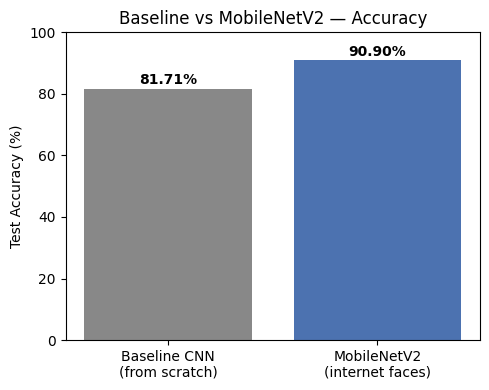

Baseline CNN test accuracy:  81.71%
MobileNetV2 test accuracy:   90.90%
Accuracy gap:                9.19 percentage points

Baseline CNN parameters:     109,889
MobileNetV2 parameters:      2,618,945

Baseline CNN file size:      1.31 MB
MobileNetV2 file size:       27.53 MB

Baseline CNN inference time: 3.30 ms/image
MobileNetV2 inference time:  16.83 ms/image


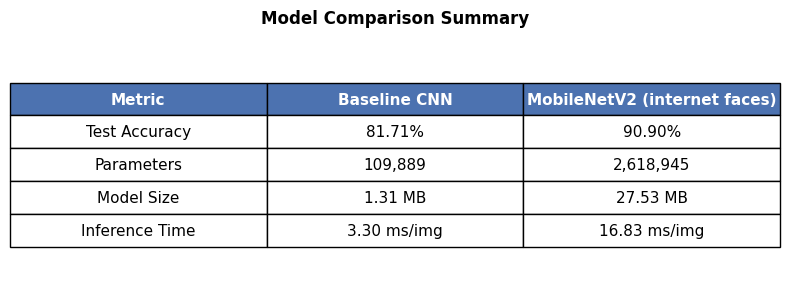


Saved comparison_accuracy.png and comparison_summary_table.png to Drive


In [ ]:
# ============================================================
# SECTION 5: MODEL COMPARISON (UPDATED)
# Baseline CNN vs Internet-Faces MobileNetV2
# ============================================================

import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model

if 'baseline_model' not in globals():
    baseline_model = load_model('/content/drive/MyDrive/baseline_cnn.h5')
    print("Loaded baseline_cnn.h5")

if 'model' not in globals():
    model = load_model('/content/drive/MyDrive/mobilenetv2_internet_faces.h5')
    print("Loaded mobilenetv2_internet_faces.h5")

preprocess_mobilenet = tf.keras.applications.mobilenet_v2.preprocess_input
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
BASE_DIR = "dataset/real_vs_fake/real-vs-fake"

# Baseline test set [0,1]
baseline_test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "test"),
    labels="inferred", label_mode="binary",
    class_names=["real", "fake"],
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
)
normalization = tf.keras.layers.Rescaling(1./255)
baseline_test_ds = baseline_test_ds.map(
    lambda x, y: (normalization(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

# MobileNet test set [-1,1]
mobilenet_test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "test"),
    labels="inferred", label_mode="binary",
    class_names=["real", "fake"],
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
)
mobilenet_test_ds = mobilenet_test_ds.map(
    lambda x, y: (preprocess_mobilenet(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

print("Evaluating Baseline CNN...")
_, baseline_test_acc = baseline_model.evaluate(baseline_test_ds, verbose=0)

print("Evaluating Internet-Faces MobileNetV2...")
_, test_acc = model.evaluate(mobilenet_test_ds, verbose=0)

plt.figure(figsize=(5, 4))
bars = plt.bar(
    ['Baseline CNN\n(from scratch)', 'MobileNetV2\n(internet faces)'],
    [baseline_test_acc * 100, test_acc * 100],
    color=['#888888', '#4C72B0']
)
plt.ylabel('Test Accuracy (%)')
plt.title('Baseline vs MobileNetV2 — Accuracy')
plt.ylim(0, 100)
for bar, v in zip(bars, [baseline_test_acc * 100, test_acc * 100]):
    plt.text(bar.get_x() + bar.get_width()/2, v + 1.5, f"{v:.2f}%",
             ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/comparison_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Baseline CNN test accuracy:  {baseline_test_acc * 100:.2f}%")
print(f"MobileNetV2 test accuracy:   {test_acc * 100:.2f}%")
print(f"Accuracy gap:                {(test_acc - baseline_test_acc) * 100:.2f} percentage points")

baseline_params = baseline_model.count_params()
mobilenet_params = model.count_params()
print(f"\nBaseline CNN parameters:     {baseline_params:,}")
print(f"MobileNetV2 parameters:      {mobilenet_params:,}")

baseline_size_mb = os.path.getsize('/content/drive/MyDrive/baseline_cnn.h5') / (1024 * 1024)
mobilenet_size_mb = os.path.getsize('/content/drive/MyDrive/mobilenetv2_internet_faces.h5') / (1024 * 1024)
print(f"\nBaseline CNN file size:      {baseline_size_mb:.2f} MB")
print(f"MobileNetV2 file size:       {mobilenet_size_mb:.2f} MB")

def measure_inference_time(m, ds, n_batches=5):
    times = []
    for images, labels in ds.take(n_batches):
        start = time.time()
        m.predict(images, verbose=0)
        elapsed = time.time() - start
        times.append(elapsed / images.shape[0])
    return np.mean(times) * 1000

baseline_infer_ms = measure_inference_time(baseline_model, baseline_test_ds)
mobilenet_infer_ms = measure_inference_time(model, mobilenet_test_ds)

print(f"\nBaseline CNN inference time: {baseline_infer_ms:.2f} ms/image")
print(f"MobileNetV2 inference time:  {mobilenet_infer_ms:.2f} ms/image")

fig, ax = plt.subplots(figsize=(8, 3))
ax.axis('off')
table_data = [
    ['Metric', 'Baseline CNN', 'MobileNetV2 (internet faces)'],
    ['Test Accuracy', f"{baseline_test_acc * 100:.2f}%", f"{test_acc * 100:.2f}%"],
    ['Parameters', f"{baseline_params:,}", f"{mobilenet_params:,}"],
    ['Model Size', f"{baseline_size_mb:.2f} MB", f"{mobilenet_size_mb:.2f} MB"],
    ['Inference Time', f"{baseline_infer_ms:.2f} ms/img", f"{mobilenet_infer_ms:.2f} ms/img"],
]
table = ax.table(cellText=table_data, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)
for i in range(len(table_data[0])):
    table[(0, i)].set_facecolor('#4C72B0')
    table[(0, i)].set_text_props(color='white', fontweight='bold')
plt.title('Model Comparison Summary', fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/comparison_summary_table.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nSaved comparison_accuracy.png and comparison_summary_table.png to Drive")

Computing baseline CNN predictions...
Computing Internet-Faces MobileNet predictions...


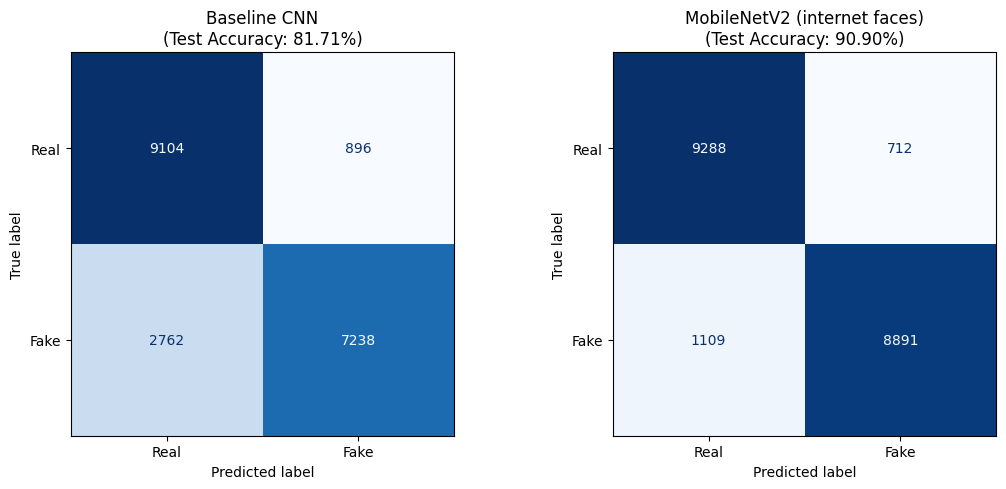

Saved comparison_confusion_matrices.png to Drive


In [ ]:
# ============================================================
# SECTION 5 (addition): Confusion matrices
# Baseline vs Internet-Faces MobileNet
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os

def get_predictions(m, ds):
    y_true, y_pred = [], []
    for images, labels in ds:
        preds = m.predict(images, verbose=0).flatten()
        y_true.extend(labels.numpy().ravel().astype(int))
        y_pred.extend((preds > 0.5).astype(int))
    return np.array(y_true), np.array(y_pred)

IMG_SIZE = (224, 224)
BATCH_SIZE = 64
BASE_DIR = "dataset/real_vs_fake/real-vs-fake"
preprocess_mobilenet = tf.keras.applications.mobilenet_v2.preprocess_input

if 'baseline_test_ds' not in globals() or 'mobilenet_test_ds' not in globals():
    print("Rebuilding test datasets with correct preprocessing...")

    baseline_test_ds = tf.keras.utils.image_dataset_from_directory(
        os.path.join(BASE_DIR, "test"),
        labels="inferred", label_mode="binary",
        class_names=["real", "fake"],
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
    )
    normalization = tf.keras.layers.Rescaling(1./255)
    baseline_test_ds = baseline_test_ds.map(
        lambda x, y: (normalization(x), y),
        num_parallel_calls=tf.data.AUTOTUNE
    ).prefetch(tf.data.AUTOTUNE)

    mobilenet_test_ds = tf.keras.utils.image_dataset_from_directory(
        os.path.join(BASE_DIR, "test"),
        labels="inferred", label_mode="binary",
        class_names=["real", "fake"],
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
    )
    mobilenet_test_ds = mobilenet_test_ds.map(
        lambda x, y: (preprocess_mobilenet(x), y),
        num_parallel_calls=tf.data.AUTOTUNE
    ).prefetch(tf.data.AUTOTUNE)

print("Computing baseline CNN predictions...")
baseline_y_true, baseline_y_pred = get_predictions(baseline_model, baseline_test_ds)

print("Computing Internet-Faces MobileNet predictions...")
mobilenet_y_true, mobilenet_y_pred = get_predictions(model, mobilenet_test_ds)

class_labels = ["Real", "Fake"]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

cm_baseline = confusion_matrix(baseline_y_true, baseline_y_pred)
ConfusionMatrixDisplay(cm_baseline, display_labels=class_labels).plot(
    ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title(f'Baseline CNN\n(Test Accuracy: {baseline_test_acc * 100:.2f}%)')

cm_mobilenet = confusion_matrix(mobilenet_y_true, mobilenet_y_pred)
ConfusionMatrixDisplay(cm_mobilenet, display_labels=class_labels).plot(
    ax=axes[1], cmap='Blues', colorbar=False
)
axes[1].set_title(f'MobileNetV2 (internet faces)\n(Test Accuracy: {test_acc * 100:.2f}%)')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/comparison_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved comparison_confusion_matrices.png to Drive")

Found 20000 files belonging to 2 classes.
Running inference on the full face test set...
Total test images: 20000

--- Classification Report ---
              precision    recall  f1-score   support

        real     0.8933    0.9288    0.9107     10000
        fake     0.9259    0.8891    0.9071     10000

    accuracy                         0.9090     20000
   macro avg     0.9096    0.9089    0.9089     20000
weighted avg     0.9096    0.9090    0.9089     20000



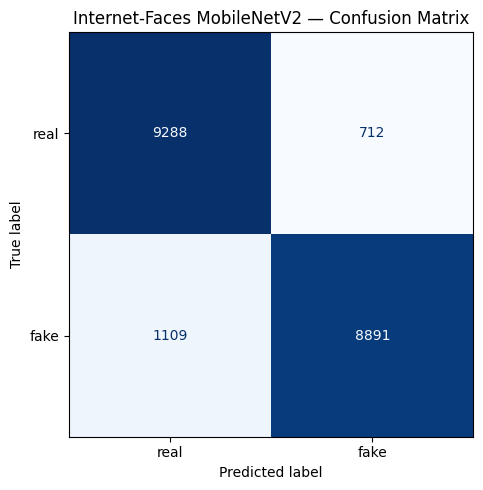

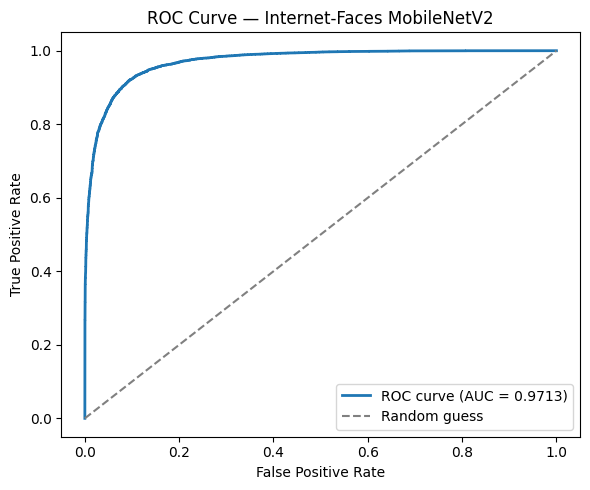

ROC-AUC: 0.9713


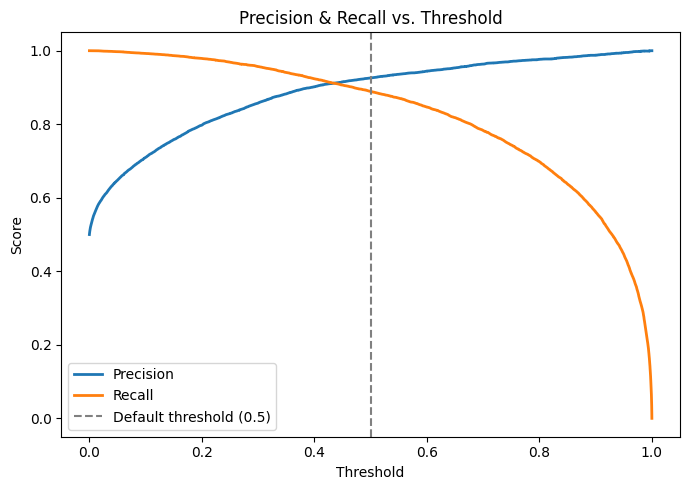


At threshold 0.5 — Precision: 0.9259, Recall: 0.8892

--- Full Test Set Error Stats ---
Total errors: 1821 (9.11% error rate)
  Real misclassified as fake: 712
  Fake misclassified as real: 1109


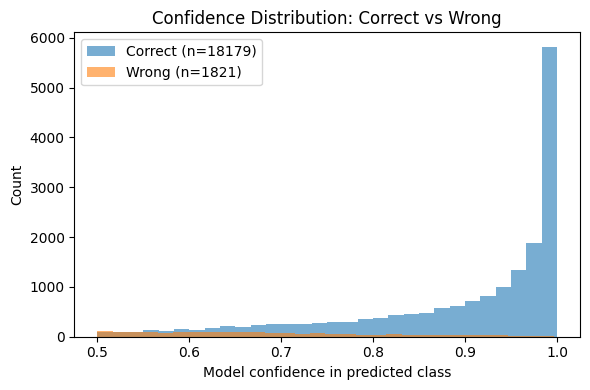

Mean confidence — correct: 0.895 | wrong: 0.685

All Section 6 outputs saved to Drive.


In [ ]:
# ============================================================
# SECTION 6A: EVALUATION (Internet-Faces MobileNetV2)
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, auc,
                             precision_recall_curve)

class_names = ["real", "fake"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
BASE_DIR = "dataset/real_vs_fake/real-vs-fake"

if 'model' not in globals():
    from tensorflow.keras.models import load_model
    model = load_model('/content/drive/MyDrive/mobilenetv2_internet_faces.h5')
    print("Loaded internet-faces MobileNet model")

preprocess_mobilenet = tf.keras.applications.mobilenet_v2.preprocess_input

# Test set with correct MobileNet preprocess [-1,1]
eval_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "test"),
    labels="inferred",
    label_mode="binary",
    class_names=["real", "fake"],
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)
eval_ds = eval_ds.map(
    lambda x, y: (preprocess_mobilenet(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

print("Running inference on the full face test set...")
y_true, y_probs = [], []
for images, labels in eval_ds:
    probs = model.predict(images, verbose=0).flatten()
    y_true.extend(labels.numpy().ravel().astype(int))
    y_probs.extend(probs)

y_true = np.array(y_true)
y_probs = np.array(y_probs)
y_pred = (y_probs > 0.5).astype(int)
print(f"Total test images: {len(y_true)}")

print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Internet-Faces MobileNetV2 — Confusion Matrix')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/eval_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

fpr, tpr, roc_thresholds = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Internet-Faces MobileNetV2')
plt.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/eval_roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"ROC-AUC: {roc_auc:.4f}")

precisions, recalls, pr_thresholds = precision_recall_curve(y_true, y_probs)
plt.figure(figsize=(7, 5))
plt.plot(pr_thresholds, precisions[:-1], label='Precision', linewidth=2)
plt.plot(pr_thresholds, recalls[:-1], label='Recall', linewidth=2)
plt.axvline(0.5, linestyle='--', color='gray', label='Default threshold (0.5)')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision & Recall vs. Threshold')
plt.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/eval_precision_recall_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()

default_idx = np.argmin(np.abs(pr_thresholds - 0.5))
print(f"\nAt threshold 0.5 — Precision: {precisions[default_idx]:.4f}, Recall: {recalls[default_idx]:.4f}")

errors = np.where(y_true != y_pred)[0]
correct = np.where(y_true == y_pred)[0]
real_error_idx = errors[y_true[errors] == 0]
fake_error_idx = errors[y_true[errors] == 1]

print(f"\n--- Full Test Set Error Stats ---")
print(f"Total errors: {len(errors)} ({len(errors)/len(y_true)*100:.2f}% error rate)")
print(f"  Real misclassified as fake: {len(real_error_idx)}")
print(f"  Fake misclassified as real: {len(fake_error_idx)}")

conf_all = np.where(y_pred == 1, y_probs, 1 - y_probs)
plt.figure(figsize=(6, 4))
plt.hist(conf_all[correct], bins=30, alpha=0.6, label=f'Correct (n={len(correct)})')
plt.hist(conf_all[errors], bins=30, alpha=0.6, label=f'Wrong (n={len(errors)})')
plt.xlabel('Model confidence in predicted class')
plt.ylabel('Count')
plt.title('Confidence Distribution: Correct vs Wrong')
plt.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/eval_confidence_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Mean confidence — correct: {conf_all[correct].mean():.3f} | wrong: {conf_all[errors].mean():.3f}")
print("\nAll Section 6 outputs saved to Drive.")

Using existing y_true / y_probs / y_pred from Section 6.

Fetching 12 specific images from face test set...
Found 20000 files belonging to 2 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_1057/3436896877.py:52: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet_colors = mpl_cm.get_cmap("jet")(np.arange(256))[:, :3]


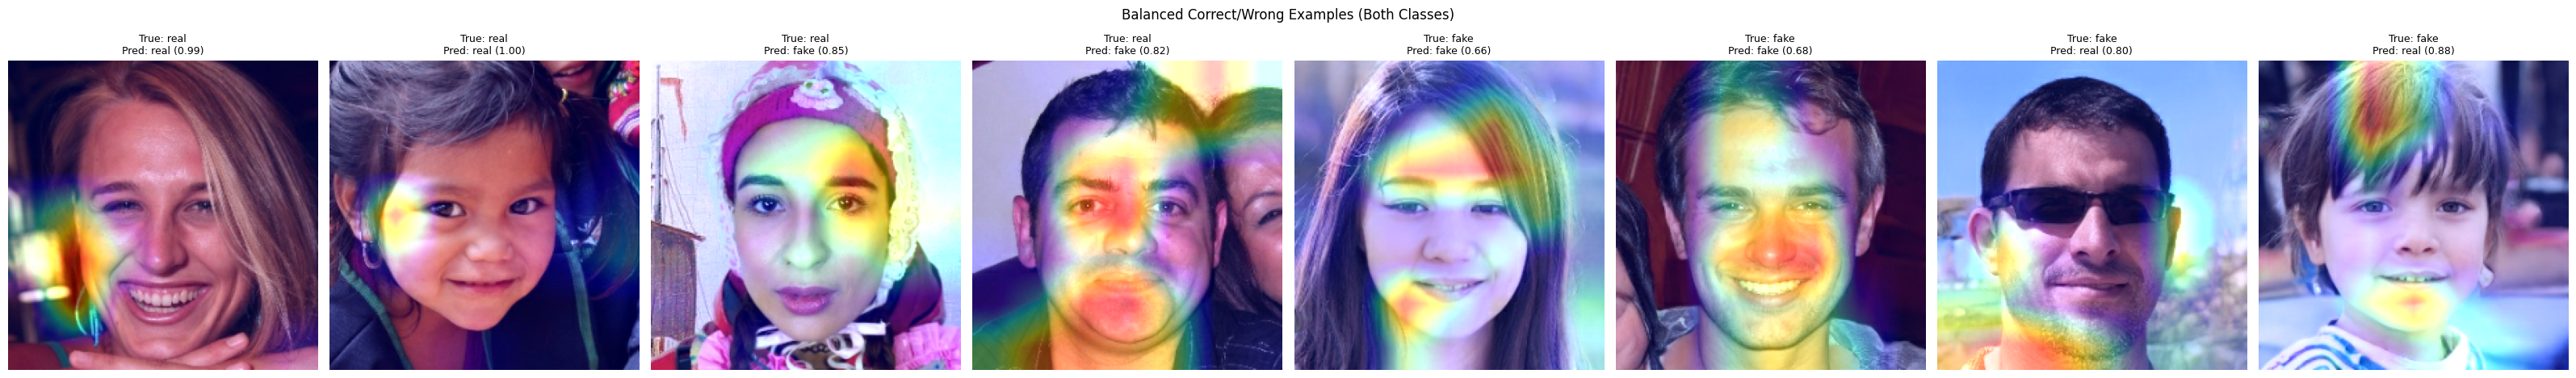

Saved gradcam_balanced.png


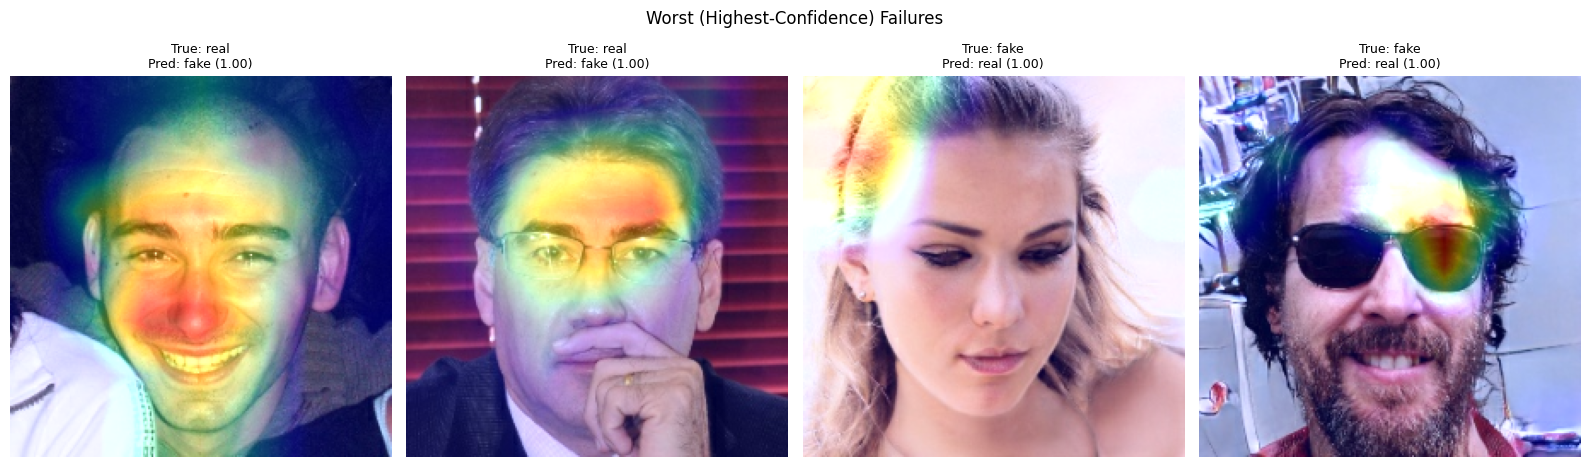

Saved gradcam_worst_errors.png

PART B: External Robustness Test

--- Upload REAL images ---


Saving real1.png to real1.png
Uploaded 1 file(s) (total real: 1). Upload another real image? (y/n): y


Saving real2.png to real2.png
Uploaded 1 file(s) (total real: 2). Upload another real image? (y/n): y


Saving real3.png to real3.png
Uploaded 1 file(s) (total real: 3). Upload another real image? (y/n): y


Saving fake.png to fake.png
Uploaded 1 file(s) (total real: 4). Upload another real image? (y/n): n

--- Now upload FAKE / AI-generated images ---


Saving fake.png to fake (1).png
Uploaded 1 file(s) (total fake: 1). Upload another fake image? (y/n): n

External test accuracy: 80.00%  (4/5 correct)


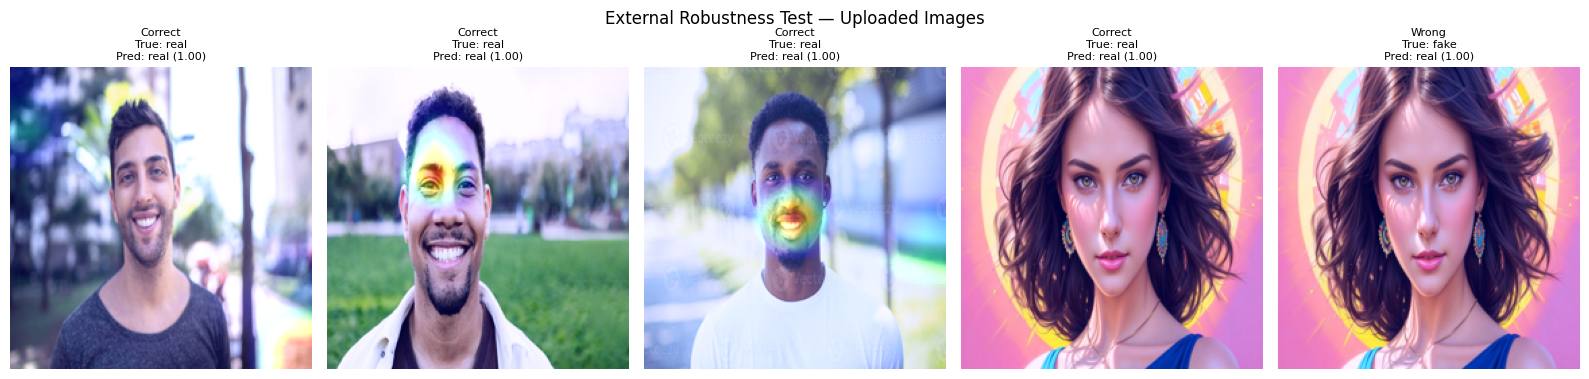

Saved external_robustness_test.png


In [ ]:
# ============================================================
# SECTION 7: INTERPRETABILITY & ROBUSTNESS
# Internet-Faces MobileNetV2
# ============================================================

import os
import io
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.cm as mpl_cm
from google.colab import files
from PIL import Image
from tensorflow.keras.models import load_model

if 'model' not in globals():
    model = load_model('/content/drive/MyDrive/mobilenetv2_internet_faces.h5')
    print("Loaded internet-faces MobileNet model")

LAST_CONV_LAYER = "out_relu"
class_names = {0: "real", 1: "fake"}
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
BASE_DIR = "dataset/real_vs_fake/real-vs-fake"
preprocess_mobilenet = tf.keras.applications.mobilenet_v2.preprocess_input

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=0):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        class_channel = predictions[:, pred_index]
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.cast(heatmap, tf.float32)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_gradcam(img01, heatmap, alpha=0.4):
    heatmap_resized = tf.image.resize(heatmap[..., np.newaxis], (img01.shape[0], img01.shape[1]))
    heatmap_resized = np.squeeze(heatmap_resized.numpy())
    jet_colors = mpl_cm.get_cmap("jet")(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[np.uint8(255 * heatmap_resized)]
    superimposed = jet_heatmap * alpha + img01
    return np.clip(superimposed, 0, 1)

# ============================================================
# PART A: Grad-CAM on face test set
# ============================================================
if 'y_true' in globals() and 'y_probs' in globals() and 'y_pred' in globals():
    print("Using existing predictions from Section 6.")
else:
    print("Recomputing predictions on face test set...")
    face_ds = tf.keras.utils.image_dataset_from_directory(
        os.path.join(BASE_DIR, "test"),
        labels="inferred", label_mode="binary",
        class_names=["real", "fake"],
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
    )
    y_true, y_probs = [], []
    for images, labels in face_ds:
        x = preprocess_mobilenet(images)
        probs = model.predict(x, verbose=0).flatten()
        y_true.extend(labels.numpy().ravel().astype(int))
        y_probs.extend(probs)
    y_true = np.array(y_true)
    y_probs = np.array(y_probs)
    y_pred = (y_probs > 0.5).astype(int)

conf_all = np.where(y_pred == 1, y_probs, 1 - y_probs)
errors = np.where(y_true != y_pred)[0]
real_error_idx = errors[y_true[errors] == 0]
fake_error_idx = errors[y_true[errors] == 1]

real_correct_idx = np.where((y_true == 0) & (y_pred == 0))[0][:2]
real_wrong_idx = real_error_idx[:2] if len(real_error_idx) else np.array([], dtype=int)
fake_correct_idx = np.where((y_true == 1) & (y_pred == 1))[0][:2]
fake_wrong_idx = fake_error_idx[:2] if len(fake_error_idx) else np.array([], dtype=int)

worst_real = real_error_idx[np.argsort(-conf_all[real_error_idx])][:2] if len(real_error_idx) else np.array([], dtype=int)
worst_fake = fake_error_idx[np.argsort(-conf_all[fake_error_idx])][:2] if len(fake_error_idx) else np.array([], dtype=int)

target_indices = set(
    np.concatenate([
        real_correct_idx, real_wrong_idx,
        fake_correct_idx, fake_wrong_idx,
        worst_real, worst_fake
    ]).tolist()
)

print(f"\nFetching {len(target_indices)} specific images from face test set...")

raw_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_DIR, "test"),
    labels="inferred", label_mode="binary",
    class_names=["real", "fake"],
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
)

found_display = {}
found_model = {}

global_i = 0
for images_batch, labels_batch in raw_ds:
    batch_np = images_batch.numpy()
    for local_i in range(batch_np.shape[0]):
        if global_i in target_indices:
            img255 = batch_np[local_i]
            found_display[global_i] = np.clip(img255 / 255.0, 0, 1)
            found_model[global_i] = preprocess_mobilenet(img255.copy())
        global_i += 1
    if len(found_display) == len(target_indices):
        break

def plot_gradcam_group(indices, title, filename):
    indices = [i for i in indices if i in found_display]
    if not indices:
        print(f"No examples found for: {title}")
        return
    n = len(indices)
    plt.figure(figsize=(4 * n, 5))
    for i, idx in enumerate(indices):
        img_disp = found_display[idx]
        img_mod = np.expand_dims(found_model[idx], axis=0)
        heatmap = make_gradcam_heatmap(img_mod, model, LAST_CONV_LAYER, pred_index=0)
        overlay = overlay_gradcam(img_disp, heatmap)
        plt.subplot(1, n, i + 1)
        plt.imshow(overlay)
        plt.title(
            f"True: {class_names[y_true[idx]]}\n"
            f"Pred: {class_names[y_pred[idx]]} ({conf_all[idx]:.2f})",
            fontsize=9
        )
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(f'/content/drive/MyDrive/{filename}', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved {filename}")

plot_gradcam_group(
    list(real_correct_idx) + list(real_wrong_idx) + list(fake_correct_idx) + list(fake_wrong_idx),
    "Balanced Correct/Wrong Examples (Internet-Faces Model)",
    "gradcam_balanced.png"
)
plot_gradcam_group(
    list(worst_real) + list(worst_fake),
    "Worst (Highest-Confidence) Failures",
    "gradcam_worst_errors.png"
)

# ============================================================
# PART B: Upload your own images
# ============================================================
print("\n" + "=" * 60)
print("PART B: External Robustness Test")
print("=" * 60)

def load_uploaded_images(label="image"):
    imgs_disp, imgs_model, names = [], [], []
    while True:
        uploaded = files.upload()
        for fname, data in uploaded.items():
            img = Image.open(io.BytesIO(data)).convert("RGB").resize(IMG_SIZE)
            arr = np.array(img).astype(np.float32)
            imgs_disp.append(np.clip(arr / 255.0, 0, 1))
            imgs_model.append(preprocess_mobilenet(arr.copy()))
            names.append(fname)
        again = input(
            f"Uploaded {len(uploaded)} file(s) (total {label}: {len(imgs_disp)}). "
            f"Upload another {label} image? (y/n): "
        )
        if again.strip().lower() != 'y':
            break
    return imgs_disp, imgs_model, names

print("\n--- Upload REAL images ---")
real_disp, real_model, real_names = load_uploaded_images(label="real")

print("\n--- Now upload FAKE / AI-generated images ---")
fake_disp, fake_model, fake_names = load_uploaded_images(label="fake")

all_disp = real_disp + fake_disp
all_model = real_model + fake_model
all_true = [0] * len(real_disp) + [1] * len(fake_disp)

ext_model = np.array(all_model)
ext_true = np.array(all_true)

if len(ext_true) > 0:
    ext_probs = model.predict(ext_model, verbose=0).flatten()
    ext_pred = (ext_probs > 0.5).astype(int)
    ext_conf = np.where(ext_pred == 1, ext_probs, 1 - ext_probs)

    ext_acc = (ext_pred == ext_true).mean()
    print(f"\nExternal test accuracy: {ext_acc*100:.2f}%  "
          f"({(ext_pred == ext_true).sum()}/{len(ext_true)} correct)")

    n = len(all_disp)
    plt.figure(figsize=(3.2 * n, 4))
    for i in range(n):
        img_array = np.expand_dims(ext_model[i], axis=0)
        heatmap = make_gradcam_heatmap(img_array, model, LAST_CONV_LAYER, pred_index=0)
        overlay = overlay_gradcam(all_disp[i], heatmap)
        plt.subplot(1, n, i + 1)
        plt.imshow(overlay)
        correct_mark = "Correct" if ext_pred[i] == ext_true[i] else "Wrong"
        plt.title(
            f"{correct_mark}\nTrue: {class_names[ext_true[i]]}\n"
            f"Pred: {class_names[ext_pred[i]]} ({ext_conf[i]:.2f})",
            fontsize=8
        )
        plt.axis("off")
    plt.suptitle("External Robustness Test — Uploaded Images")
    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/external_robustness_test.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved external_robustness_test.png")
else:
    print("No images uploaded.")

In [ ]:
# ============================================================
# Polished Gradio UI — Real vs Fake Detector
# ============================================================
!pip install -q gradio

import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.models import load_model
import gradio as gr

MODEL_PATH = "/content/drive/MyDrive/mobilenetv2_internet_faces.h5"
model = load_model(MODEL_PATH)
preprocess = tf.keras.applications.mobilenet_v2.preprocess_input

def predict_image(img):
    if img is None:
        return (
            "<div style='padding:16px;border-radius:12px;background:#f3f4f6;color:#374151;font-size:16px;'>Please upload an image first.</div>",
            {"REAL": 0.0, "FAKE": 0.0},
            "Waiting for image"
        )

    img = img.convert("RGB").resize((224, 224))
    arr = np.array(img).astype("float32")
    x = preprocess(arr)
    x = np.expand_dims(x, axis=0)

    p_fake = float(model.predict(x, verbose=0).flatten()[0])
    p_real = 1.0 - p_fake

    if p_fake > 0.5:
        label = "FAKE"
        conf = p_fake
        badge_color = "#dc2626"
        bg = "#fef2f2"
        note = "This image is likely AI-generated / deepfake."
    else:
        label = "REAL"
        conf = p_real
        badge_color = "#16a34a"
        bg = "#f0fdf4"
        note = "This image is likely a real photograph."

    if 0.40 <= p_fake <= 0.60:
        note += " Model confidence is low — treat as uncertain."

    result_html = f"""
    <div style="padding:18px;border-radius:14px;background:{bg};border:1px solid {badge_color}22;">
      <div style="display:inline-block;padding:6px 14px;border-radius:999px;background:{badge_color};color:white;font-weight:700;font-size:14px;letter-spacing:0.5px;">
        {label}
      </div>
      <div style="margin-top:14px;font-size:28px;font-weight:800;color:{badge_color};">
        {conf*100:.1f}% confidence
      </div>
      <div style="margin-top:10px;color:#374151;font-size:14px;line-height:1.5;">
        P(real) = {p_real:.4f}<br>
        P(fake) = {p_fake:.4f}
      </div>
    </div>
    """

    probs = {"REAL": p_real, "FAKE": p_fake}
    return result_html, probs, note


css = """
.gradio-container {max-width: 980px !important; margin: auto;}
h1 {text-align: center; font-weight: 800 !important;}
"""

with gr.Blocks(theme=gr.themes.Soft(primary_hue="blue", neutral_hue="slate"), css=css, title="AI Image Detector") as demo:
    gr.Markdown(
        """
        # Deepfake / AI Image Detector
        Upload a **face or photo** and check if it looks **REAL** or **FAKE (AI-generated)**.

        <p style="text-align:center;color:#6b7280;font-size:14px;margin-top:-6px;">
        Research demo using MobileNetV2 · Face test accuracy ≈ 90.9% · Not perfect on every internet image
        </p>
        """
    )

    with gr.Row(equal_height=True):
        with gr.Column(scale=1):
            input_image = gr.Image(
                type="pil",
                label="Upload Image",
                height=380,
                sources=["upload", "clipboard"]
            )
            with gr.Row():
                submit_btn = gr.Button("Check Image", variant="primary", scale=2)
                clear_btn = gr.Button("Clear", scale=1)

        with gr.Column(scale=1):
            result_html = gr.HTML(label="Result")
            prob_label = gr.Label(label="Class Probabilities", num_top_classes=2)
            note_box = gr.Textbox(label="Summary", lines=2, interactive=False)

    gr.Markdown(
        """
        ### How to read results
        | Result | Meaning |
        |--------|---------|
        | **REAL** | Model thinks it is a real photo |
        | **FAKE** | Model thinks it is AI-generated |
        | Confidence near **50%** | Uncertain — do not trust strongly |

        **Tip:** Use clear, front-facing face images for best results.
        """
    )

    submit_btn.click(
        fn=predict_image,
        inputs=input_image,
        outputs=[result_html, prob_label, note_box]
    )
    clear_btn.click(
        fn=lambda: (None, "<div style='padding:16px;color:#6b7280;'>Upload an image to begin.</div>", {"REAL": 0.0, "FAKE": 0.0}, ""),
        inputs=None,
        outputs=[input_image, result_html, prob_label, note_box]
    )

demo.launch(share=True)